# 3.1 Molecular backbones show multi-dimensional complementarity

**Figure 1** (per-task matched-seed complementarity across the 10 base models) and **Table S1** (per-task held-out-test performance). Recomputed from `../data/recompute_data/` via the shared setup cell.

In [1]:
# === Setup: figure/table regeneration for the ADMET multi-representation fusion paper ===
# Self-contained RECOMPUTATION from source predictions.
# Every figure/table quantity is recomputed here from raw per-seed per-molecule predictions
# (recompute_data/predictions/{model}.parquet), the per-model TDC leaderboard rankings
# (recompute_data/leaderboards/{model}.csv, direct training outputs), the 1023-subset uniform
# fusion sweep (recompute_data/clean_stage1_current.csv, all1023.csv), and the leaderboard
# ruler (recompute_data/tdc_leaderboard_snapshot.json). Nothing below is a hard-coded result;
# task metadata (ADMET group, training-set size, mechanism rationale) is loaded from
# recompute_data/task_metadata.json (fixed design labels, not recomputed). assert blocks verify the recomputed numbers against the
# manuscript values.
import os, json, io, itertools
from math import factorial
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import spearmanr, kendalltau, wilcoxon
from sklearn.metrics import roc_auc_score, average_precision_score, mean_absolute_error
from statsmodels.stats.multitest import multipletests

HERE = os.path.dirname(os.path.abspath("__file__")) if "__file__" in globals() else os.getcwd()
RELDATA = os.path.join(HERE, "..", "data")          # release data/ dir (single canonical copy)
DATA = os.path.join(RELDATA, "recompute_data")
OUTDIR = os.path.join(HERE, "..", "figures"); os.makedirs(OUTDIR, exist_ok=True)  # write figures into release figures/ dir
META_GREY = "#888888"

def apply_figure_style(*, frame="open", font=None, sizes=(8, 7, 6), grid=False):
    import matplotlib as mpl
    if frame not in ("open", "boxed", "none"):
        raise ValueError(f"frame must be 'open'|'boxed'|'none', got {frame!r}")
    try:
        import os, sys, glob, matplotlib.font_manager as fm
        fdir = os.path.join(os.environ.get("CONDA_PREFIX") or sys.prefix, "fonts")
        if os.path.isdir(fdir):
            known = {f.fname for f in fm.fontManager.ttflist}
            for f in glob.glob(os.path.join(fdir, "*.ttf")):
                if f not in known:
                    fm.fontManager.addfont(f)
    except Exception:
        pass
    base, secondary, tick = sizes
    boxed = (frame == "boxed")
    rc = {
        "font.family": "sans-serif", "font.size": base, "axes.labelsize": base,
        "axes.titlesize": base, "legend.fontsize": secondary, "xtick.labelsize": tick,
        "ytick.labelsize": tick, "axes.linewidth": 0.6,
        "xtick.direction": "out", "ytick.direction": "out",
        "xtick.major.size": 3, "ytick.major.size": 3,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "axes.spines.top": boxed, "axes.spines.right": boxed,
        "axes.spines.left": frame != "none", "axes.spines.bottom": frame != "none",
        "axes.grid": bool(grid), "legend.frameon": False,
        "figure.dpi": 200, "savefig.dpi": 300, "savefig.bbox": "tight",
        "axes.titleweight": "normal", "axes.titlelocation": "left",
        "axes.labelweight": "normal", "lines.linewidth": 1.2, "patch.linewidth": 0.6,
        "pdf.fonttype": 42, "ps.fonttype": 42,
    }
    if font:
        rc["font.sans-serif"] = [font, "DejaVu Sans"]
    mpl.rcParams.update(rc)

REG  = json.load(open(f"{DATA}/task_registry.json"))
SNAP = json.load(open(f"{DATA}/tdc_leaderboard_snapshot.json"))
MODELS = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer","mtl_map",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer","stl_map"]
TASKS  = [t for t in REG if t != "Bioavailability_Ma"]  # 21 evaluation tasks

def metric(name, y, p):
    """Compute a single TDC metric (mae/auroc/auprc/spearman) after dropping NaN labels."""
    y = np.asarray(y, float); p = np.asarray(p, float); m = ~np.isnan(y); y, p = y[m], p[m]
    if name == "mae":      return float(mean_absolute_error(y, p))
    if name == "auroc":    return float(roc_auc_score(y, p))
    if name == "auprc":    return float(average_precision_score(y, p))
    if name == "spearman": return float(spearmanr(y, p)[0])
    raise KeyError(name)

def norm_pct(score, task):
    """norm_score = fraction of TDC leaderboard models we beat (metric-direction aware)."""
    e = SNAP.get(task)
    if e is None or np.isnan(score): return np.nan
    s = [m["score"] for m in e["models"].values()]; met = REG[task]["metric"]
    worse = (sum(1 for x in s if x > score) if met == "mae" else sum(1 for x in s if x < score))
    return worse / len(s)

def rank_of(score, task):
    """Leaderboard rank of `score` for `task` (1 = best), metric-direction aware."""
    e = SNAP.get(task); met = REG[task]["metric"]
    s = [m["score"] for m in e["models"].values()]
    return (sum(1 for x in s if x < score) if met == "mae" else sum(1 for x in s if x > score)) + 1

# ---- load predictions (add replicate counter for exact merge keys) ----
PRED = {}
for m in MODELS:
    d = pd.read_parquet(f"{DATA}/predictions/{m}.parquet")
    PRED[m] = d.assign(rep=d.groupby(["seed","task","split","smiles"]).cumcount())

def merge_uniform(models, within):
    """Inner-join the given models' per-molecule predictions; add `yhat` = their uniform mean.
    within=True keeps the seed axis (matched-seed track); within=False averages predictions
    across seeds first (seed-averaged track). Returns the merged long DataFrame."""
    keys = ["seed","task","split","smiles","rep"] if within else ["task","split","smiles","rep"]
    if within:
        base = PRED[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(PRED[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    else:
        sm = {m: PRED[m].groupby(["task","split","smiles","rep"])
                       .agg(y_true=("y_true","first"), y_pred=("y_pred","mean")).reset_index() for m in models}
        base = sm[models[0]][keys+["y_true","y_pred"]].rename(columns={"y_pred":f"p_{models[0]}"})
        for m in models[1:]:
            base = base.merge(sm[m][keys+["y_pred"]].rename(columns={"y_pred":f"p_{m}"}), on=keys, how="inner")
    base["yhat"] = base[[f"p_{m}" for m in models]].mean(axis=1)
    return base

def pertask_norm(models, within):
    """{task: norm_score} for the uniform-mean fusion of `models`, on the held-out test set.
    within=True: score each seed then average the per-seed norm; within=False: score once on
    the seed-averaged predictions."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            seed_sc = [metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]
            res[task] = norm_pct(float(np.mean(seed_sc)), task)
        else:
            res[task] = norm_pct(metric(met, t.y_true, t.yhat), task)
    return res

def pertask_raw(models, within):
    """{task: raw_score} for the uniform-mean fusion of `models`, held-out test set.
    Mirror of pertask_norm but returns the raw metric value (before leaderboard normalization).
    within=True: mean over the per-seed metric (matched-seed track)."""
    base = merge_uniform(models, within); res = {}
    for task in TASKS:
        met = REG[task]["metric"]
        t = base[(base.task==task)&(base.split=="test")].dropna(subset=["y_true"])
        if within:
            res[task] = float(np.mean([metric(met, g.y_true, g.yhat) for _, g in t.groupby("seed")]))
        else:
            res[task] = float(metric(met, t.y_true, t.yhat))
    return res

def subset_norm(models, within):
    """Mean of pertask_norm across the 21 evaluation tasks (one scalar per subset)."""
    return float(np.mean(list(pertask_norm(models, within).values())))

# ---- correlation matrices (exact XAI method) ----
def corr_matrices(within):
    """Mean off-diagonal |correlation| among the k=5 ensemble members, for both the
    standardized predictions and the standardized residuals (prediction - truth).

    Returns (pred_corr, resid_corr): how redundant the members' outputs / errors are.
    within=True  -> matched-seed track: correlate per (task, seed), average the matrices.
    within=False -> seed-averaged track: pool all test rows per task, correlate once.
    (This is the exact 'XAI' correlation recipe used in the analysis notebooks.)
    """
    pred_cols = [f"p_{m}" for m in ENSEMBLE]
    base = merge_uniform(ENSEMBLE, within)
    if not within:
        # seed-averaged: concatenate standardized vectors across all tasks, one corr matrix
        pred_z  = {m: [] for m in ENSEMBLE}   # standardized predictions per member
        resid_z = {m: [] for m in ENSEMBLE}   # standardized residuals per member
        for task in TASKS:
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            for j, m in enumerate(ENSEMBLE):
                p = preds[:, j]; pred_z[m].append((p - p.mean())/(p.std()+1e-9))
                resid = p - y_true; resid_z[m].append((resid - resid.mean())/(resid.std()+1e-9))
        pred_z  = {m: np.concatenate(v) for m, v in pred_z.items()}
        resid_z = {m: np.concatenate(v) for m, v in resid_z.items()}
        pred_corr_mat  = np.corrcoef([pred_z[m]  for m in ENSEMBLE])
        resid_corr_mat = np.corrcoef([resid_z[m] for m in ENSEMBLE])
    else:
        # matched-seed: one corr matrix per (task, seed), then average across all of them
        seeds = sorted(base.seed.unique()); pred_mats = []; resid_mats = []
        for task in TASKS:
            task_rows = base[base.task==task]
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows) < 3: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                pred_z_seed = []; resid_z_seed = []
                for j, m in enumerate(ENSEMBLE):
                    p = preds[:, j]
                    pred_z_seed.append((p - p.mean())/(p.std()+1e-9))
                    resid_z_seed.append((p - y_true) - (p - y_true).mean()/((p - y_true).std()+1e-9))
                pred_mats.append(np.corrcoef(pred_z_seed)); resid_mats.append(np.corrcoef(resid_z_seed))
        pred_corr_mat  = np.nanmean(pred_mats, 0)
        resid_corr_mat = np.nanmean(resid_mats, 0)
    upper = np.triu_indices(len(ENSEMBLE), 1)   # off-diagonal (unordered pairs)
    return float(np.abs(pred_corr_mat[upper]).mean()), float(np.abs(resid_corr_mat[upper]).mean())

# ---- winners + best-single mean rank ----
def winners_best(within):
    """Per-task winner counts among the k=5 members + the best single member's mean TDC rank.

    Returns (wins, best_model, best_mean_rank):
      wins           - {model: number of tasks where it is the single best member}
      best_model     - member with the lowest mean leaderboard rank across tasks
      best_mean_rank - that member's mean rank (the single-model baseline the ensemble beats)
    within=True  -> matched-seed: winner decided per (task, seed); rank from seed-mean score.
    within=False -> seed-averaged: winner decided once per task on the seed-averaged score.
    """
    from collections import Counter
    base = merge_uniform(ENSEMBLE, within); pred_cols = [f"p_{m}" for m in ENSEMBLE]
    if not within:
        wins = Counter(); member_ranks = {m: [] for m in ENSEMBLE}   # per-task leaderboard rank
        for task in TASKS:
            met = REG[task]["metric"]
            rows = base[(base.split=="test")&(base.task==task)].dropna(subset=["y_true"])
            y_true = rows.y_true.to_numpy(float); preds = rows[pred_cols].to_numpy(float)
            member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
            wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
            for m in ENSEMBLE: member_ranks[m].append(rank_of(member_score[m], task))
    else:
        seeds = sorted(base.seed.unique()); wins = Counter(); member_score_by_task = {m: [] for m in ENSEMBLE}
        for task in TASKS:
            met = REG[task]["metric"]; task_rows = base[base.task==task]; seed_scores = {m: [] for m in ENSEMBLE}
            for seed in seeds:
                seed_rows = task_rows[(task_rows.seed==seed)&(task_rows.split=="test")].dropna(subset=["y_true"])
                if len(seed_rows)==0: continue
                y_true = seed_rows.y_true.to_numpy(float); preds = seed_rows[pred_cols].to_numpy(float)
                member_score = {m: metric(met, y_true, preds[:, j]) for j, m in enumerate(ENSEMBLE)}
                wins[(min if met=="mae" else max)(member_score, key=member_score.get)] += 1
                for m in ENSEMBLE: seed_scores[m].append(member_score[m])
            for m in ENSEMBLE: member_score_by_task[m].append(np.mean(seed_scores[m]))
        member_ranks = {m: [rank_of(member_score_by_task[m][i], TASKS[i]) for i in range(len(TASKS))] for m in ENSEMBLE}
    best_model = min(ENSEMBLE, key=lambda m: np.mean(member_ranks[m]))
    return dict(wins), best_model, float(np.mean(member_ranks[best_model]))

# ---- ensemble mean TDC rank (Score-then-Rank), within + cross ----
def ensemble_mean_rank():
    """Mean TDC leaderboard rank of the k=5 ensemble across tasks (Score-then-Rank).
    Returns (mean_rank_within, mean_rank_cross)."""
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False)
    ranks_w = []; ranks_c = []
    for task in TASKS:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ranks_w.append(rank_of(float(np.mean(seed_sc)), task))
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        ranks_c.append(rank_of(metric(met, tc.y_true, tc.yhat), task))
    return float(np.mean(ranks_w)), float(np.mean(ranks_c))

# ---- LOO + Shapley (over all 31 non-empty subsets of ENSEMBLE) ----
def loo_shapley():
    """Leave-one-out and Shapley contribution of each k=5 member to the ensemble norm_score.

    Enumerates all 31 non-empty subsets of ENSEMBLE and scores each (within + cross track):
      loo_within/cross    = value(full) - value(full minus this member)  (removal effect)
      shapley_within/cross= mean marginal contribution over all coalitions (Shapley value)
    Returns (per_member_dict, value_full_within, value_full_cross).
    """
    value_within = {}; value_cross = {}
    for size in range(1, len(ENSEMBLE)+1):
        for combo in itertools.combinations(ENSEMBLE, size):
            key = tuple(sorted(combo))
            value_within[key] = subset_norm(list(combo), True)
            value_cross[key]  = subset_norm(list(combo), False)
    full = tuple(sorted(ENSEMBLE)); n_members = len(ENSEMBLE)
    def shapley(value):
        contrib = {m: 0.0 for m in ENSEMBLE}
        for m in ENSEMBLE:
            others = [x for x in ENSEMBLE if x != m]
            for size in range(len(others)+1):
                for coalition in itertools.combinations(others, size):
                    weight = factorial(len(coalition))*factorial(n_members-len(coalition)-1)/factorial(n_members)
                    with_m    = value[tuple(sorted(coalition+(m,)))]
                    without_m = value[tuple(sorted(coalition))] if coalition else 0.0
                    contrib[m] += weight*(with_m - without_m)
        return contrib
    shap_within = shapley(value_within); shap_cross = shapley(value_cross); out = {}
    for m in ENSEMBLE:
        out[m] = {
            "within_solo": value_within[(m,)],
            "loo_within":  value_within[full] - value_within[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "cross_solo":  value_cross[(m,)],
            "loo_cross":   value_cross[full]  - value_cross[tuple(sorted(x for x in ENSEMBLE if x!=m))],
            "shapley_within": shap_within[m], "shapley_cross": shap_cross[m]}
    return out, value_within[full], value_cross[full]

# ---- MAP vs mean/max aggregation (leaderboard.csv `ours` -> re-ranked) ----
def map_agg():
    """MAP (joint latent fusion) vs naive mean/best aggregation of the 3 shared backbones,
    per training regime (mtl/stl). Uses leaderboard.csv `ours` scores re-normalized against
    the TDC snapshot. Returns (summary_dict, long_leaderboard_df)."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    def to_norm(ds, score):
        e = SNAP.get(ds)
        if e is None or pd.isna(score): return np.nan
        met = REG[ds]["metric"]; s = [x["score"] for x in e["models"].values()]
        rank = (sum(1 for x in s if x < score) if met=="mae" else sum(1 for x in s if x > score))+1
        return (len(s)-rank+1)/len(s)
    BACKS = ["chemeleon","graphmvp","molformer"]; res = {}
    for train in ["mtl","stl"]:
        bm = [f"{train}_{b}" for b in BACKS]
        piv = LONG[LONG.model.isin(bm)].pivot_table(index=["dataset","metric"], columns="model", values="ours", aggfunc="first")
        mp = LONG[LONG.model==f"{train}_map"].set_index("dataset").apply(lambda r: to_norm(r.name, r["ours"]), axis=1)
        mn = {}; mx = {}
        for (ds,met),row in piv.iterrows():
            vals = row[bm].dropna()
            if vals.empty: continue
            direction = SNAP.get(ds,{}).get("direction","higher")
            mn[ds] = to_norm(ds, vals.mean()); mx[ds] = to_norm(ds, vals.max() if direction=="higher" else vals.min())
        common = [d for d in mp.index if d in mn]
        mpv = mp[common]; mnv = pd.Series(mn)[common]; mxv = pd.Series(mx)[common]
        res[train] = {"map":round(float(mpv.mean()),3),"mean":round(float(mnv.mean()),3),"best":round(float(mxv.mean()),3),
                      "map_gt_mean":f"{int((mpv>mnv).sum())}/{len(common)}",
                      "map_gt_best":f"{int((mpv>mxv).sum())}/{len(common)}","n":len(common)}
    return res, LONG

# ---- ensemble-size sweep (top-20 mean per k over 1023 uniform subsets) ----
def ksweep():
    # clean_stage1_current.csv: the Stage-1 ensemble-size selection sweep over all 1,023
    #   non-empty uniform-mean subsets of the 10 backbones, scored on VALIDATION only.
    #   One row per subset; columns: k, bases (comma-joined member list),
    #   simple_{within,cross}_{norm,rank,ntask} (uniform-mean blending).
    #   (The file also carries legacy weighted_*/ridge_* meta-learner columns from an
    #   earlier design; the paper uses uniform-mean only, so they are ignored here.)
    #   Feeds Figure 3 + Table S3 (validation top-20-mean norm_score per k -> elbow at k=5).
    #   NOTE: this is NOT a duplicate of all1023.csv - it holds validation-only scores under
    #   several blending rules, whereas all1023.csv holds uniform val AND test scores. The
    #   validation columns differ numerically (max abs diff ~0.038) because they come from
    #   different scoring passes, and only all1023.csv carries the test columns Figure 4a needs.
    s1 = pd.read_csv(f"{DATA}/clean_stage1_current.csv")
    s1["k"] = s1.bases.apply(lambda b: len(b.split(",")))
    def topN(col, N=20):
        return {k: round(s1[s1.k==k].nlargest(min(N,(s1.k==k).sum()), col)[col].mean(),4) for k in range(1,11)}
    tw = topN("simple_within_norm"); tc = topN("simple_cross_norm")
    rows = []
    for k in range(1,11):
        rows.append([k, tw[k], round(tw[k]-tw[k-1],4) if k>1 else None,
                        tc[k], round(tc[k]-tc[k-1],4) if k>1 else None])
    return rows

# ---- validation->test rank reliability (all 1023 subsets) ----
def val_test_corr():
    # all1023.csv: uniform-mean fusion scored on BOTH validation and the fixed TDC test set,
    #   for every one of the 1,023 non-empty subsets. One row per subset; columns:
    #   combo_key (member list), k, val_within, val_cross, test_within, test_cross,
    #   val_comb, test_comb. This is the source for Figure 4a's validation->test rank
    #   reliability scatter, which REQUIRES the test_* columns (absent from clean_stage1).
    #   Complementary to, not a duplicate of, clean_stage1_current.csv (see ksweep()).
    from scipy.stats import spearmanr as _sp, kendalltau as _kt
    a = pd.read_csv(f"{DATA}/all1023.csv"); out = {}
    for name,vc,tc in [("within","val_within","test_within"),("cross","val_cross","test_cross"),("combined","val_comb","test_comb")]:
        out[name] = {"rho": round(_sp(a[vc],a[tc])[0],4), "tau": round(_kt(a[vc],a[tc])[0],4)}
    out["n_configs"] = len(a); return out

# ---- statistical tests (ensemble vs deployable singles + per-task oracle) ----
def stat_tests():
    ens_w = pertask_norm(ENSEMBLE, True); ens_c = pertask_norm(ENSEMBLE, False)
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    LONG = pd.concat(lbs, ignore_index=True); LONG = LONG[LONG.dataset != "Bioavailability_Ma"]
    LONG["norm"] = (LONG.n_total - LONG["rank"] + 1)/LONG.n_total
    lbp = LONG.pivot_table(index="dataset", columns="model", values="norm").loc[TASKS]
    baselines = {"CheMeleon\u00b7STL":"stl_chemeleon","MAP\u00b7STL":"stl_map","D-MPNN\u00b7MTL":"mtl_dmpnn"}
    dep = {}; ora = {}
    for track, ens in [("within", ens_w), ("cross", ens_c)]:
        e = np.array([ens[t] for t in TASKS])
        for disp, m in baselines.items():
            b = lbp[m].to_numpy(); de = e - b; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
            dep[f"{disp}|{track}"] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
                "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(b.mean())}
        oc = lbp.max(axis=1).to_numpy(); de = e - oc; w = wilcoxon(de, alternative="greater", zero_method="wilcox")
        ora[track] = {"median":float(np.median(de)),"mean":float(de.mean()),"W":float(w.statistic),
            "p":float(w.pvalue),"wtl":f"{int((de>0).sum())}/{int((de==0).sum())}/{int((de<0).sum())}","base_mean":float(oc.mean())}
    return {"deployable_single":dep, "per_task_oracle":ora, "n_tasks":len(TASKS),
            "ensemble_mean":{"within":float(np.mean(list(ens_w.values()))),"cross":float(np.mean(list(ens_c.values())))}}

# ---- per-task tables t1 (per-backbone), t3 (MAP/mean/max), t4 (ensemble) ----
def leaderboard_long():
    """Concatenate every model's leaderboard.csv into one long frame with a `norm` column."""
    lbs = []
    for m in MODELS:
        d = pd.read_csv(f"{DATA}/leaderboards/{m}.csv"); d["model"] = m; lbs.append(d)
    L = pd.concat(lbs, ignore_index=True)
    L["norm"] = (L.n_total - L["rank"] + 1)/L.n_total
    return L

def table_t1(meta):
    """per-backbone per-task raw+norm on the WITHIN-SEED (matched-seed) basis: each seed is
    scored separately, mapped to a per-seed norm_score, then averaged over seeds (identical
    basis to Figure 1a / Table 3). meta = {task:{group,n}}. norm rounded to 3 decimals."""
    BB = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
          "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
    raw = {b: pertask_raw([b], True)  for b in BB}
    nrm = {b: pertask_norm([b], True) for b in BB}
    rows = []
    for task, mrec in meta.items():
        e = {"group": mrec["group"], "dataset": task, "n": mrec["n"], "metric": REG[task]["metric"]}
        for b in BB:
            e[b] = {"raw": round(float(raw[b][task]),3), "norm": round(float(nrm[b][task]),3)}
        rows.append(e)
    return rows

def table_t3(meta3):
    """MAP / latent-mean / latent-best per-task raw+norm on the WITHIN-SEED basis. MAP is the
    joint-fusion model's own per-seed prediction; latent mean/best aggregate the three backbones'
    per-seed scores (mean or direction-aware best) per seed, then norm and average. meta3 = {task:{group}}."""
    BACKS = ["chemeleon","graphmvp","molformer"]
    def agg_within(train, task, how):  # returns (raw, norm) within-seed for score-space mean/best
        met = REG[task]["metric"]; per_raw = []; per_norm = []
        seeds = sorted(PRED[f"{train}_{BACKS[0]}"].seed.unique())
        for seed in seeds:
            sc = []
            for bb in BACKS:
                d = PRED[f"{train}_{bb}"]
                t = d[(d.task==task)&(d.split=="test")&(d.seed==seed)].dropna(subset=["y_true"])
                sc.append(metric(met, t.y_true, t.y_pred))
            agg = np.mean(sc) if how=="mean" else (min(sc) if met=="mae" else max(sc))
            per_raw.append(agg); per_norm.append(norm_pct(agg, task))
        return float(np.mean(per_raw)), float(np.mean(per_norm))
    map_raw = {tr: pertask_raw([f"{tr}_map"], True)  for tr in ["mtl","stl"]}
    map_nrm = {tr: pertask_norm([f"{tr}_map"], True) for tr in ["mtl","stl"]}
    rows = []
    for task, mrec in meta3.items():
        met = REG[task]["metric"]; e = {"group": mrec["group"], "dataset": task, "metric": met}
        for train in ["mtl","stl"]:
            e[f"{train}_map"]  = {"raw": round(float(map_raw[train][task]),3), "norm": round(float(map_nrm[train][task]),3)}
            mr, mn = agg_within(train, task, "mean"); br, bn = agg_within(train, task, "best")
            e[f"{train}_mean"] = {"raw": round(mr,3), "norm": round(mn,3)}
            e[f"{train}_best"] = {"raw": round(br,3), "norm": round(bn,3)}
        rows.append(e)
    return rows

def table_t4():
    """ensemble per-task within/cross score+norm+rank over ALL 22 tasks (incl Bioavailability_Ma)."""
    allt = list(REG)
    bw = merge_uniform(ENSEMBLE, True); bc = merge_uniform(ENSEMBLE, False); rows = []
    for task in allt:
        met = REG[task]["metric"]
        tw = bw[(bw.task==task)&(bw.split=="test")].dropna(subset=["y_true"])
        seed_sc = [metric(met, g.y_true, g.yhat) for _, g in tw.groupby("seed")]
        ws = float(np.mean(seed_sc)); ws_std = float(np.std(seed_sc, ddof=0))  # ddof=0 matches TDC ours_std
        tc = bc[(bc.task==task)&(bc.split=="test")].dropna(subset=["y_true"])
        cs = metric(met, tc.y_true, tc.yhat)
        def _n(x, nd=3):  # int for exact 0/1 (match hardcoded schema), else float rounded to nd
            return int(x) if float(x).is_integer() else round(float(x), nd)
        rows.append({"task":task, "metric":met,
                     "within_score":round(ws,6), "within_std":round(ws_std,6), "within_norm":_n(norm_pct(ws,task),3), "within_rank":rank_of(ws,task),
                     "cross_score":round(cs,6),  "cross_norm":_n(norm_pct(cs,task),3),  "cross_rank":rank_of(cs,task)})
    return rows

# ---- Figure-1 within-seed solo + per-task (predictions basis) ----
def fig1_data(groups):
    """Figure 1 inputs on the within-seed (matched-seed) basis: per-model solo norm_score
    (`solo`), per-model per-task norm (`pertask`), and the ADMET mechanism `groups`."""
    solo = {m: subset_norm([m], True) for m in MODELS}
    pertask = []
    for task in TASKS:
        rec = {"task": task}
        for m in MODELS:
            rec[m] = pertask_norm([m], True)[task]
        pertask.append(rec)
    return {"solo": solo, "pertask": pertask, "groups": groups}

# ---- assemble full _GT / _PT / _FIG1 / _ST ----
def build_all(meta1, meta3, groups, t2, const_gt):
    lo, ens_w, ens_c = loo_shapley()
    cw = corr_matrices(True); cc = corr_matrices(False)
    win_w, bs_w, bsr_w = winners_best(True); win_c, bs_c, bsr_c = winners_best(False)
    mag, _ = map_agg()
    GT = dict(const_gt)  # final_ensemble, headline, sota_tasks, etc (constants)
    GT["map_agg"] = {t: {k: mag[t][k] for k in ["map","mean","best","map_gt_mean","map_gt_best"]} for t in ["mtl","stl"]}
    GT["ksweep"] = ksweep()
    GT["corr"] = {"within": {"pred_offdiag": round(cw[0],3), "resid_offdiag": round(cw[1],3)},
                  "cross":  {"pred_offdiag": round(cc[0],3), "resid_offdiag": round(cc[1],3)}}
    # ens_rank = mean TDC rank of the k=5 uniform ensemble across the 21 tasks (Score-then-Rank),
    # recomputed here (NOT a literal): within uses per-seed→mean→rank, cross uses seed-meaned→rank.
    ens_rank_w, ens_rank_c = ensemble_mean_rank()
    GT["best_single"] = {"within": {"model": bs_w, "mean_rank": round(bsr_w,3), "ens_rank": round(ens_rank_w,3)},
                         "cross":  {"model": bs_c, "mean_rank": round(bsr_c,3), "ens_rank": round(ens_rank_c,3)}}
    # per member -> [0]=within_solo  [1]=loo_within  [2]=cross_solo
    #                [3]=loo_cross    [4]=shapley_within  [5]=shapley_cross
    GT["loo_shapley"] = {b: [round(lo[b]["within_solo"],4), round(lo[b]["loo_within"],4),
                             round(lo[b]["cross_solo"],4), round(lo[b]["loo_cross"],4),
                             round(lo[b]["shapley_within"],4), round(lo[b]["shapley_cross"],4)] for b in ENSEMBLE}
    GT["winners"] = {"cross": {m: win_c.get(m,0) for m in ENSEMBLE},
                     "within_taskseed": {m: win_w.get(m,0) for m in ENSEMBLE}}
    GT["full_ensemble_norm"] = {"within": round(ens_w,4), "cross": round(ens_c,4)}
    PT = {"t1": table_t1(meta1), "t3": table_t3(meta3), "t4": table_t4(), "t2": t2}
    FIG1 = fig1_data(groups)
    ST = stat_tests()
    return GT, PT, FIG1, ST


# --- task metadata (fixed design labels, not recomputed): loaded from recompute_data/task_metadata.json ---
_TASK_META = json.load(open(f"{DATA}/task_metadata.json"))
_META1   = _TASK_META["meta1"]                                   # {task: {group, n}}
_META3   = {t: {"group": v["group"]} for t, v in _META1.items()} # meta1 without training-set size
_GROUPS  = _TASK_META["groups"]                                  # {mechanism group: [tasks]}
_T2      = _TASK_META["t2"]                                      # [{group, tasks, rationale}]
_CONST_GT = _TASK_META["const_gt"]                               # final_ensemble / final_composition / ...
ENSEMBLE  = list(_CONST_GT["final_ensemble"])                    # final k=5 members (single source of truth)


# --- recompute everything from source ---
_GT, _PT, _FIG1, _ST = build_all(_META1, _META3, _GROUPS, _T2, _CONST_GT)

# --- solo per-task within/cross norm (recomputed from predictions+leaderboards; replaces solo_pertask_within_cross.csv / fig1_within_pertask.csv) ---
# Per-(model, task) solo within/cross norm_score, recomputed from source predictions +
# leaderboard rankings. Replaces the released solo_pertask_within_cross.csv and
# fig1_within_pertask.csv (values verified identical to 1e-16).
# Row order matters ONLY for Figure 4d's winner-per-task argmax under exact norm ties
# (several tasks tie to the 4th decimal); we emit rows in the exact model/task order of
# the original fig1_within_pertask.csv so idxmax tie-breaking reproduces the published
# Figure 4d winner distribution (8/5/4/3/1). The norm values themselves are order-independent.
_SOLO_MODEL_ORDER = ["mtl_dmpnn","stl_dmpnn","stl_map","stl_chemeleon","stl_graphmvp",
                     "stl_molformer","mtl_graphmvp","mtl_molformer","mtl_chemeleon","mtl_map"]
_SOLO_TASK_ORDER  = ["HIA_Hou","Pgp_Broccatelli","BBB_Martins","CYP2C9_Veith","CYP2D6_Veith",
                     "CYP3A4_Veith","CYP2C9_Substrate_CarbonMangels","CYP2D6_Substrate_CarbonMangels",
                     "CYP3A4_Substrate_CarbonMangels","hERG","AMES","DILI","Caco2_Wang",
                     "Lipophilicity_AstraZeneca","Solubility_AqSolDB","PPBR_AZ","VDss_Lombardo",
                     "Half_Life_Obach","Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ","LD50_Zhu"]
def _solo_pertask_frame():
    per_model_within = {m: pertask_norm([m], True)  for m in _SOLO_MODEL_ORDER}
    per_model_cross  = {m: pertask_norm([m], False) for m in _SOLO_MODEL_ORDER}
    rows = []
    for m in _SOLO_MODEL_ORDER:
        for t in _SOLO_TASK_ORDER:
            rows.append({"model": m, "task": t,
                         "group":  _META1.get(t, {}).get("group", ""),
                         "metric": REG[t]["metric"],
                         "within_norm": per_model_within[m][t],
                         "cross_norm":  per_model_cross[m][t]})
    return pd.DataFrame(rows)
_SOLO_PT = _solo_pertask_frame()   # 210 rows = 10 backbones x 21 evaluation tasks

# --- assert recomputed values reproduce the manuscript (tolerance = rounding) ---
assert abs(_FIG1["solo"]["stl_chemeleon"] - 0.6331) < 0.002, _FIG1["solo"]["stl_chemeleon"]
assert abs(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8539) < 0.002
assert abs(np.mean([e["cross_norm"]  for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]) - 0.8971) < 0.002
assert _GT["winners"]["cross"]["mtl_dmpnn"] == 6 and _GT["winners"]["within_taskseed"]["mtl_dmpnn"] == 36
assert abs(_GT["map_agg"]["mtl"]["map"] - 0.621) < 0.002 and abs(_GT["map_agg"]["stl"]["map"] - 0.609) < 0.002
assert abs(_GT["corr"]["cross"]["pred_offdiag"] - 0.878) < 0.002 and abs(_GT["corr"]["within"]["pred_offdiag"] - 0.767) < 0.002
assert abs(_GT["ksweep"][4][1] - 0.7877) < 0.002 and abs(_GT["ksweep"][3][1] - 0.7825) < 0.002
assert abs(_GT["best_single"]["cross"]["mean_rank"] - 5.476) < 0.01 and abs(_GT["best_single"]["within"]["mean_rank"] - 8.429) < 0.01
assert len(_PT["t1"]) == 21 and len(_PT["t3"]) == 21 and len(_PT["t4"]) == 22

print("setup ok | recomputed from source | tasks:", len(_PT["t1"]),
      "| final ensemble:", _GT["final_ensemble"],
      "| ens within/cross norm:", round(np.mean([e["within_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4),
      round(np.mean([e["cross_norm"] for e in _PT["t4"] if e["task"]!="Bioavailability_Ma"]),4))


# --- consolidated-workbook helpers (from tables notebook) ---
OUT = "../tables"; os.makedirs(OUT, exist_ok=True)
TABLES = {}
def register(name, df, index=False):
    TABLES[name] = (df, index)
    df.to_csv(os.path.join(OUT, name + ".csv"), index=index)
    return df

BACKBONES = ["mtl_dmpnn","mtl_chemeleon","mtl_graphmvp","mtl_molformer",
             "stl_dmpnn","stl_chemeleon","stl_graphmvp","stl_molformer"]
BB_LABEL  = {"mtl_dmpnn":"D-MPNN MTL","mtl_chemeleon":"CheMeleon MTL","mtl_graphmvp":"GraphMVP MTL",
             "mtl_molformer":"MoLFormer MTL","stl_dmpnn":"D-MPNN STL","stl_chemeleon":"CheMeleon STL",
             "stl_graphmvp":"GraphMVP STL","stl_molformer":"MoLFormer STL"}
def cell(d):  # "raw (norm_score)" — norm shown to 3 decimals (unified precision)
    return f'{d["raw"]:g} ({d["norm"]:.3f})'
print("recomputed pertask + ground_truth from source; backbones:", len(BACKBONES),
      "| S1 tasks:", len(_PT["t1"]), "| ksweep k:", len(_GT["ksweep"]))


setup ok | recomputed from source | tasks: 21 | final ensemble: ['mtl_dmpnn', 'mtl_molformer', 'stl_chemeleon', 'stl_graphmvp', 'stl_map'] | ens within/cross norm: 0.854 0.8971
recomputed pertask + ground_truth from source; backbones: 8 | S1 tasks: 21 | ksweep k: 10


# 3.1 Molecular backbones show multi-dimensional complementarity

## Fig. 1 Complementarity across the 10 base models.

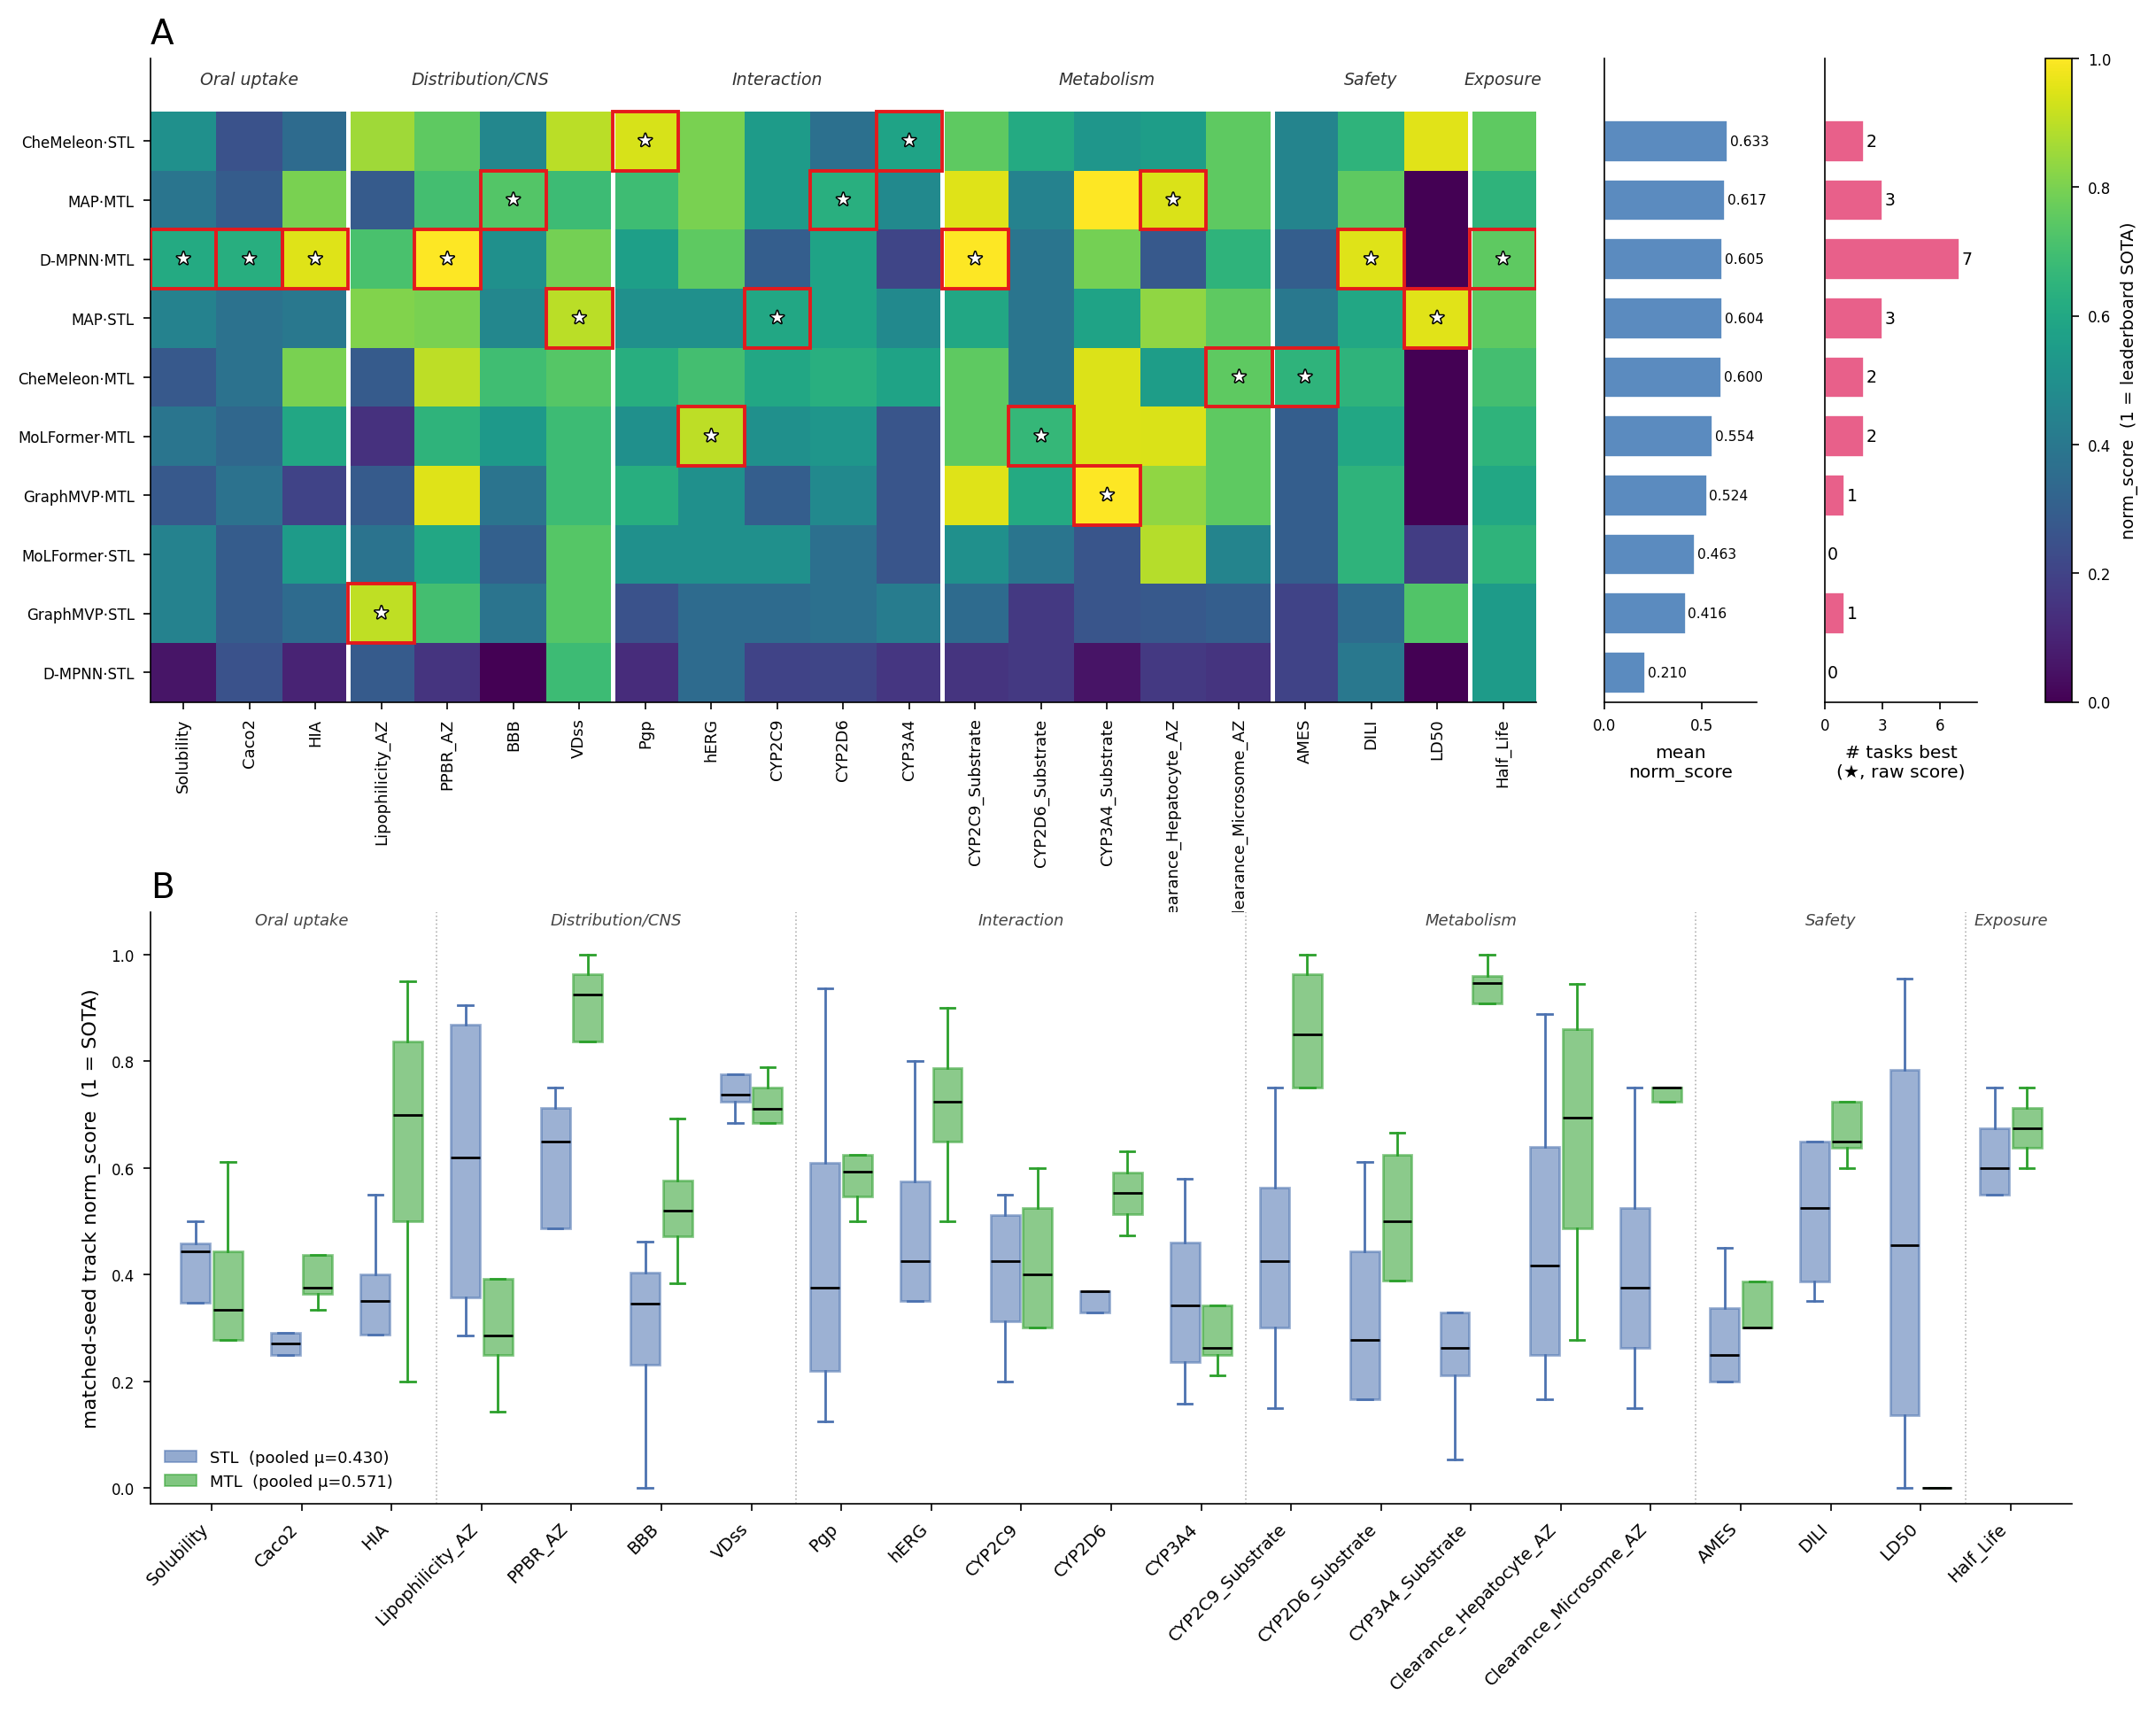

In [2]:
# === figure1.png (within-seed / matched-seed track basis) ===
import json, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.patches import Patch, Rectangle
from matplotlib.gridspec import GridSpec
apply_figure_style(sizes=(8,7,6))

# _FIG1 recomputed in setup cell (solo/pertask within-seed basis + groups constant)

PRETTY = {"stl_chemeleon":"CheMeleon\u00b7STL","mtl_chemeleon":"CheMeleon\u00b7MTL",
 "stl_map":"MAP\u00b7STL","mtl_map":"MAP\u00b7MTL","stl_dmpnn":"D-MPNN\u00b7STL","mtl_dmpnn":"D-MPNN\u00b7MTL",
 "stl_graphmvp":"GraphMVP\u00b7STL","mtl_graphmvp":"GraphMVP\u00b7MTL","stl_molformer":"MoLFormer\u00b7STL","mtl_molformer":"MoLFormer\u00b7MTL"}
SHORT = {"Solubility_AqSolDB":"Solubility","Caco2_Wang":"Caco2","HIA_Hou":"HIA","Lipophilicity_AstraZeneca":"Lipophilicity_AZ",
 "PPBR_AZ":"PPBR_AZ","BBB_Martins":"BBB","VDss_Lombardo":"VDss","Pgp_Broccatelli":"Pgp","hERG":"hERG",
 "CYP2C9_Veith":"CYP2C9","CYP2D6_Veith":"CYP2D6","CYP3A4_Veith":"CYP3A4","CYP2C9_Substrate_CarbonMangels":"CYP2C9_Substrate",
 "CYP2D6_Substrate_CarbonMangels":"CYP2D6_Substrate","CYP3A4_Substrate_CarbonMangels":"CYP3A4_Substrate",
 "Clearance_Hepatocyte_AZ":"Clearance_Hepatocyte_AZ","Clearance_Microsome_AZ":"Clearance_Microsome_AZ",
 "AMES":"AMES","DILI":"DILI","LD50_Zhu":"LD50","Half_Life_Obach":"Half_Life"}
FINAL5 = {"mtl_dmpnn","mtl_molformer","stl_chemeleon","stl_graphmvp","stl_map"}
STLc,MTLc = "#4c72b0","#2ca02c"
GROUPS = _FIG1["groups"]

# ---- panel a data: 10-model x 21-task per-task norm_score heatmap ----
solo = _FIG1["solo"]; pt = {e["task"]:e for e in _FIG1["pertask"]}
row_models = [m for m,_ in sorted(solo.items(), key=lambda kv:-kv[1])]  # rows: descending mean solo norm
task_order = [t for g in GROUPS.values() for t in g]                    # cols: mechanism-group order
Mmat = np.array([[pt[t][m] for t in task_order] for m in row_models])
# Star / red box = per-task BEST model by RAW score (direction-aware: mae -> min, else max),
# NOT by norm_score. norm_score is a step function (fraction of leaderboard beaten), so many
# models land on the same norm rung and would tie spuriously; raw score gives one true winner
# per task (matches the Figure 5b raw-score ranking). Heatmap colour still shows norm_score.
_rawpt = {m: pertask_raw([m], True) for m in row_models}                # within-seed raw per task
best_mask = np.zeros_like(Mmat, dtype=bool)                            # best per task (col), raw-score
for j, t in enumerate(task_order):
    met = REG[t]["metric"]
    vals = np.array([_rawpt[m][t] for m in row_models])
    tgt = vals.min() if met == "mae" else vals.max()
    best_mask[np.abs(vals - tgt) <= 1e-9, j] = True
avg_norm  = np.array([solo[m] for m in row_models])                    # per-model mean norm_score
ntask_best= best_mask.sum(axis=1)                                      # per-model # tasks best
n_rows, n_cols = Mmat.shape

# ---- panel b data: per-task STL vs MTL norm (boxplots, no raw points) ----
bb = ["dmpnn","chemeleon","graphmvp","molformer"]
stl_by_task = [[pt[t]["stl_"+b] for b in bb] for t in task_order]
mtl_by_task = [[pt[t]["mtl_"+b] for b in bb] for t in task_order]
stl_all = np.array([v for r in stl_by_task for v in r]); mtl_all = np.array([v for r in mtl_by_task for v in r])

plt.close('all')
fig = plt.figure(figsize=(14.0,10.6))
outer = GridSpec(2,1,height_ratios=[1.0,0.92],hspace=0.34)
# --- panel a: heatmap + two side bars ---
gsA = outer[0].subgridspec(1,4,width_ratios=[n_cols,2.3,2.3,0.4],wspace=0.16)
axH = fig.add_subplot(gsA[0]); axV = fig.add_subplot(gsA[1]); axN = fig.add_subplot(gsA[2]); axC = fig.add_subplot(gsA[3])
star_pe=[pe.withStroke(linewidth=1.1, foreground="black")]

im = axH.imshow(Mmat, aspect="auto", cmap="viridis", vmin=0, vmax=1)
axH.set_yticks(range(n_rows)); axH.set_yticklabels([PRETTY[m] for m in row_models])
axH.set_xticks(range(n_cols)); axH.set_xticklabels([SHORT[t] for t in task_order], rotation=90, fontsize=6.5)
for i in range(n_rows):
    for j in range(n_cols):
        if best_mask[i,j]:
            axH.add_patch(Rectangle((j-0.5,i-0.5),1,1,fill=False,edgecolor="#e41a1c",lw=1.4,zorder=4))
            axH.text(j,i,"\u2605",ha="center",va="center",color="white",fontsize=6.8,zorder=5,path_effects=star_pe)
acc=0
for gname,tasks in GROUPS.items():
    st,en=acc,acc+len(tasks); acc=en
    if st>0: axH.axvline(st-0.5,color="white",lw=1.8)
    axH.text((st+en-1)/2,-0.9,gname,ha="center",va="bottom",fontsize=6.8,style="italic",color="#333")
axH.set_ylim(n_rows-0.5,-1.4)
axH.set_title("A", fontsize=14)
# axH.set_title("a  No single model dominates all tasks \u2014 per-task norm_score (21 TDC ADMET tasks)",
#               loc="left",fontweight="bold",fontsize=9.5)

y=np.arange(n_rows)
axV.barh(y, avg_norm, color="#5b8bbf", height=0.7, edgecolor="white")
for yi,v in zip(y,avg_norm): axV.text(v+0.012,yi,f"{v:.3f}",va="center",ha="left",fontsize=5.6)
axV.set_ylim(n_rows-0.5,-1.4); axV.set_yticks([]); axV.set_xlim(0,0.78); axV.set_xticks([0,0.5])
axV.set_xlabel("mean\nnorm_score", fontsize=7.3)

axN.barh(y, ntask_best, color="#e8608a", height=0.7, edgecolor="white")
for yi,v in zip(y,ntask_best): axN.text(v+0.12,yi,str(int(v)),va="center",ha="left",fontsize=6.8)
axN.set_ylim(n_rows-0.5,-1.4); axN.set_yticks([]); axN.set_xlim(0,ntask_best.max()+0.9); axN.set_xticks([0,3,6])
axN.set_xlabel("# tasks best\n(\u2605, raw score)", fontsize=7.3)
cb=fig.colorbar(im, cax=axC)
cb.set_label("norm_score  (1 = leaderboard SOTA)", fontsize=7)

# --- panel b: MTL vs STL per-task boxplots (no raw points) ---
axB = fig.add_subplot(outer[1])
n=len(task_order); xpos=np.arange(n); w=0.36
bpS=axB.boxplot(stl_by_task,positions=xpos-w/2,widths=w*0.9,patch_artist=True,showfliers=False,medianprops=dict(color="black",lw=1))
bpM=axB.boxplot(mtl_by_task,positions=xpos+w/2,widths=w*0.9,patch_artist=True,showfliers=False,medianprops=dict(color="black",lw=1))
for b in bpS["boxes"]: b.set(facecolor=STLc,alpha=0.55,edgecolor=STLc)
for b in bpM["boxes"]: b.set(facecolor=MTLc,alpha=0.55,edgecolor=MTLc)
for bp,cc in [(bpS,STLc),(bpM,MTLc)]:
    for wk in bp["whiskers"]: wk.set(color=cc)
    for cap in bp["caps"]: cap.set(color=cc)
axB.set_xticks(xpos); axB.set_xticklabels([SHORT[t] for t in task_order],rotation=45,ha="right",fontsize=7)
axB.set_ylabel("matched-seed track norm_score  (1 = SOTA)"); axB.set_ylim(-0.03,1.08)
axB.set_title("B", fontsize=14)
# axB.set_title("b  MTL vs STL: neither wins every task",loc="left",fontweight="bold",fontsize=9)
axB.legend(handles=[Patch(color=STLc,alpha=0.6,label=f"STL  (pooled \u03bc={stl_all.mean():.3f})"),Patch(color=MTLc,alpha=0.6,label=f"MTL  (pooled \u03bc={mtl_all.mean():.3f})")],loc="lower left",fontsize=6.5,frameon=False)
acc=0
for gname,tasks in GROUPS.items():
    st,en=acc,acc+len(tasks); acc=en
    if st>0: axB.axvline(st-0.5,color="grey",ls=":",lw=0.6,alpha=0.6)
    axB.text((st+en-1)/2,1.05,gname,ha="center",va="bottom",fontsize=6.5,style="italic",color="#444")
fig.savefig(os.path.join(OUTDIR,"figure1.png"), dpi=300, bbox_inches="tight")
plt.show()


*Fig. 1 Complementarity across the 10 base models. (a) Per-task matched-seed held-out-test norm_score (1 = leaderboard SOTA) for all 10 base models—the four backbones (D-MPNN, CheMeleon, GraphMVP, MoLFormer) and the joint-fusion MAP model, each under STL and MTL—across the 21 TDC ADMET tasks, grouped by mechanism (Table 2). Cell colour encodes norm_score, and the first right-hand bar ("mean norm_score") gives each model's average norm_score over the 21 tasks, so that rows are ordered from the strongest overall model at the top to the weakest at the bottom. Because norm_score is a discrete leaderboard-rank score on which several models often share the same value, the per-task winner is instead determined on the underlying raw metric (with direction handled appropriately): on each task the single best-performing model is outlined in red and marked with an asterisk, and the second right-hand bar ("# tasks best") counts, for each model, the number of tasks on which it is that winner. MAP is shown here because it is itself a candidate late-fusion member (Section 2.4), so the panel displays the full candidate pool from which the 1,023 subsets of Section 3.2 are formed. (b) Per-task matched-seed norm_score distributions for MTL versus STL, restricted to the four backbones (same matched-seed basis as panel a) and grouped by ADMET mechanism. MAP is excluded from this panel because it aggregates three of the backbones, so its STL/MTL contrast would be confounded by the fusion module and its inclusion would double-count those encoders; the pooled averages quoted in the text (μ = 0.571 for MTL vs 0.430 for STL) are computed over the four backbones only.*


## Table S1. Per-task held-out-test performance for all 10 base models

The four backbones (D-MPNN, CheMeleon, GraphMVP, MoLFormer) and the joint-fusion MAP model, each under MTL and STL. Each cell: raw metric (rank-normalized score). Norm_score 1 = leaderboard SOTA. MAP is a feature-level joint fusion over three of the backbones (Section 2.3) and is included here because it is one of the 10 candidates from which the 1,023 subsets are formed.

In [3]:
# Table S1
_t3_by_ds = {e["dataset"]: e for e in _PT["t3"]}
rows=[]
for e in _PT["t1"]:
    m = _t3_by_ds[e["dataset"]]
    base_cells = [cell(e[b]) for b in BACKBONES]
    map_cells  = [cell(m["mtl_map"]), cell(m["stl_map"])]
    rows.append([e["group"], e["dataset"], e["n"], e["metric"]] + base_cells + map_cells)
cols=["Group","Dataset","N","Metric"] + [BB_LABEL[b] for b in BACKBONES] + ["MAP MTL","MAP STL"]
S1=pd.DataFrame(rows, columns=cols)
S1 = S1[['Group', 'Dataset', 'N', 'Metric',
 'D-MPNN MTL', 'CheMeleon MTL', 'GraphMVP MTL', 'MoLFormer MTL', 'MAP MTL',
 'D-MPNN STL', 'CheMeleon STL', 'GraphMVP STL', 'MoLFormer STL', 'MAP STL']]
register("tableS1_per_backbone_pertask", S1)
# verify against manuscript SI (Caco2_Wang, D-MPNN MTL = 0.322 (0.62)); MAP columns match leaderboard basis
assert S1.iloc[0]["Dataset"]=="Caco2_Wang" and S1.iloc[0]["D-MPNN MTL"]=="0.322 (0.625)", S1.iloc[0].to_dict()
assert S1.iloc[0]["MAP MTL"]=="0.443 (0.292)", S1.iloc[0]["MAP MTL"]
assert len(S1)==21 and S1.shape[1]==4+8+2
print("S1 OK", S1.shape); S1.head(3)


S1 OK (21, 14)


,Group,Dataset,N,Metric,D-MPNN MTL,CheMeleon MTL,GraphMVP MTL,MoLFormer MTL,MAP MTL,D-MPNN STL,CheMeleon STL,GraphMVP STL,MoLFormer STL,MAP STL
0,oral_uptake,Caco2_Wang,910,mae,0.322 (0.625),0.36 (0.375),0.392 (0.375),0.401 (0.333),0.443 (0.292),0.463 (0.250),0.461 (0.250),0.431 (0.292),0.419 (0.292),0.37 (0.375)
1,oral_uptake,HIA_Hou,578,auroc,0.991 (0.950),0.988 (0.800),0.929 (0.200),0.981 (0.600),0.987 (0.800),0.851 (0.100),0.958 (0.350),0.953 (0.350),0.977 (0.550),0.97 (0.400)
2,oral_uptake,Solubility_AqSolDB,9982,mae,0.822 (0.611),0.95 (0.278),0.983 (0.278),0.916 (0.389),0.931 (0.389),1.102 (0.056),0.828 (0.500),0.897 (0.444),0.868 (0.444),0.844 (0.444)
